## Trabajo práctico — Árboles de decisión

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42

### 3. Ejercicio 1 — Partidos de tenis

**Parte B — Con Python y scikit-learn:** una vez concluida la parte A, entrenar un `DecisionTreeClassifier(criterion="entropy")` con los mismos ejemplos y comparar su estructura y sus predicciones con el árbol dibujado a mano:

1. Leer el archivo `play_tennis.csv`, comprobar los nombres de las variables y construir `X` e `y`.
2. Codifique las variables categóricas utilizando `OneHotEncoder`.
3. Entrenar un `DecisionTreeClassifier` con `criterion="entropy"` y `random_state=42`, sin limitar inicialmente la profundidad.
4. Dibujar el árbol con `plot_tree` de scikit-learn, mostrando nombres de variables, entropía, cantidad de ejemplos y clases, determinar su profundidad, cantidad de nodos y hojas.
5. Compararlo con la **resolución en papel**: ¿coinciden las divisiones? ¿Puede cambiar la orientación Sí/No de una pregunta equivalente? ¿Cómo se representa una condición categórica binaria después de `OneHotEncoder`?

['ID', 'Pronostico', 'Humedad', 'Viento', 'Juega']
   ID Pronostico Humedad Viento Juega
0   1    soleado    alta     no    no
1   2    nublado    alta     no    sí
2   3   lluvioso  normal     no    sí
3   4   lluvioso  normal     sí    no
4   5    soleado    alta     no    no


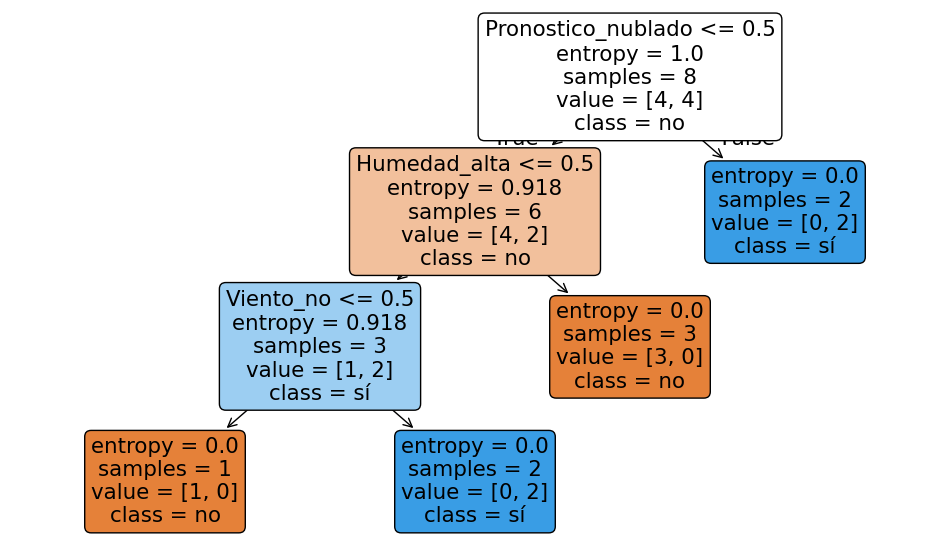

Profundidad: 3
Nodos totales: 7
Hojas: 4


In [2]:
# 1. Leer el archivo y comprobar los nombres de las variables
datos = pd.read_csv("./play_tennis.csv") 
print(datos.columns.tolist()) #vemos nombres exactos (con o sin tildes)
print(datos.head())

# Separar predictores (X) y etiqueta (y)
X = datos.drop(columns=["Juega", "ID"])   #el ID no nos sirve es para numerar las filas nomas
y = datos["Juega"]

# 2. Codificar variables categóricas con OneHotEncoder ---
# Cada categoría pasa a ser una columna 0/1 (ej: Pronostico_nublado = 1 si es nublado, 0 si no).
encoder = OneHotEncoder(sparse_output=False)   
X_enc = encoder.fit_transform(X)
feature_names = encoder.get_feature_names_out()
# aca no hay train/test: el objetivo es comparar la estructura con el arbol que hicimos,
# por eso ajustamos el encoder con todos los datos.

# 3. Entrenar arbol, sin limitar la profundidad 
arbol = DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE)
arbol.fit(X_enc, y)

# 4. Dibujar arbol y obtener sus medidas
plt.figure(figsize=(12, 7))
plot_tree(arbol, feature_names=feature_names, class_names=arbol.classes_,
          filled=True, rounded=True, impurity=True)   # impurity=True muestra la entropía de cada nodo
plt.show()

print("Profundidad:", arbol.get_depth())
print("Nodos totales:", arbol.tree_.node_count)
print("Hojas:", arbol.get_n_leaves())

**Comparación**: 

La orientación no coincide en todos los nodos porque en el papel rotamos las ramas para acomodar el dibujo, pero cada pregunta separa los mismos ejemplos que en scikit-learn. Después de OneHotEncoder, cada categoría queda en su propia columna con valores 0 y 1, por lo que una condición categórica binaria se expresa como un umbral <= 0.5, donde la rama izquierda corresponde al 0, es decir, que no pertenece a la categoría, y la derecha al 1, sí pertenece.

### 4. Ejercicio 2 — Iris: regiones de decisión, generalización y sobreajuste

En esta actividad se trabajará con el dataset **Iris** y con dos variables continuas:

- `petal length (cm)` (longitud del pétalo).
- `petal width (cm)` (ancho del pétalo).

El objetivo es relacionar **estructura del árbol**, **regiones del espacio de características** y **diferencias entre los resultados de entrenamiento y prueba**.

**Consignas:**

1. Cargar el dataset Iris, usando `load_iris()` seleccionar únicamente las dos características indicadas. Separar **70 % para entrenamiento y 30 % para prueba** (`random_state=42`, `stratify=y`).

2. Entrenar árboles con `criterion="entropy"` y `max_depth=2` y `max_depth=3`. Graficar cada árbol y sus regiones de decisión, marcando los datos de entrenamiento.

3. Entrenar otro árbol sin límite de profundidad (`max_depth=None`). Registrar para los tres modelos: profundidad obtenida, número de hojas, accuracy de entrenamiento y accuracy de prueba. Comparar: ¿más profundidad aumenta siempre el accuracy de entrenamiento? ¿Aumenta necesariamente el de prueba?

4. Explorar una restricción de **pre-poda**, por ejemplo `min_samples_leaf=4`. Comparar profundidad, número de hojas y resultados con los de un árbol sin ese límite.

5. Explicar qué representan en `plot_tree`: `entropy`, `samples`, `value` y `class`. Relacionar al menos un umbral con una frontera visible en el gráfico de regiones.

In [3]:
def plot_decision_regions(model, X, y, class_names, feature_names, title, resolution=240):
    """Plot a 2D decision map with observed samples overlaid."""
    x_min, x_max = X[:, 0].min() - 0.35, X[:, 0].max() + 0.35
    y_min, y_max = X[:, 1].min() - 0.25, X[:, 1].max() + 0.25

    x_grid = np.linspace(x_min, x_max, resolution)
    y_grid = np.linspace(y_min, y_max, resolution)
    xx, yy = np.meshgrid(x_grid, y_grid)
    grid_points = np.column_stack([xx.ravel(), yy.ravel()])
    predictions = model.predict(grid_points).reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.contourf(xx, yy, predictions, levels=[-0.5, 0.5, 1.5, 2.5], cmap="Pastel1", alpha=0.85)
    for class_id, class_name in enumerate(class_names):
        mask = y == class_id
        ax.scatter(X[mask, 0], X[mask, 1], s=30, label=class_name,
                   edgecolors="black", linewidths=0.35, alpha=0.8)
    ax.set(xlabel=feature_names[0], ylabel=feature_names[1], title=title)
    ax.legend(title="Real class")
    fig.tight_layout()
    plt.show()

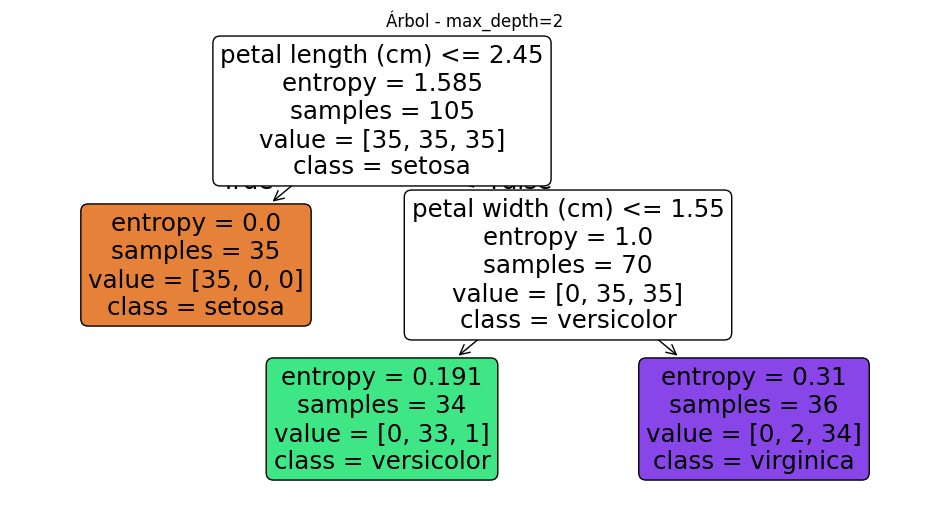

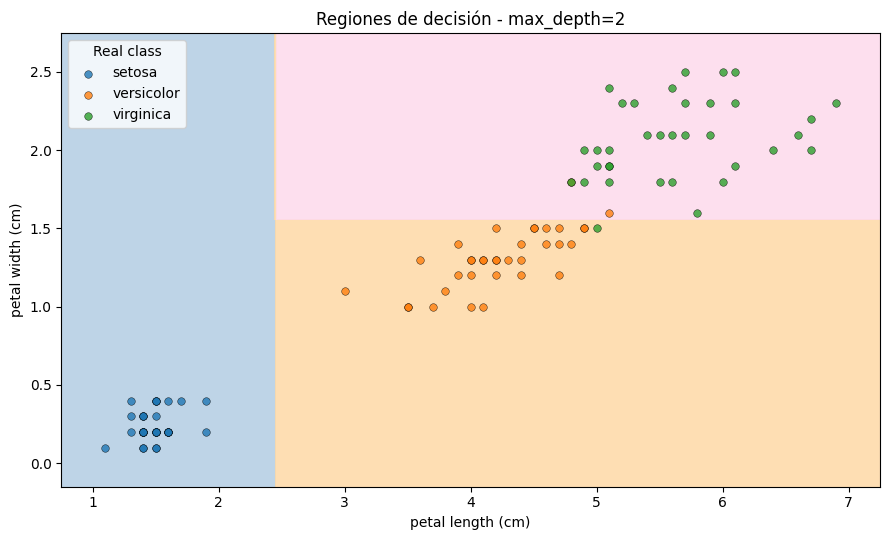

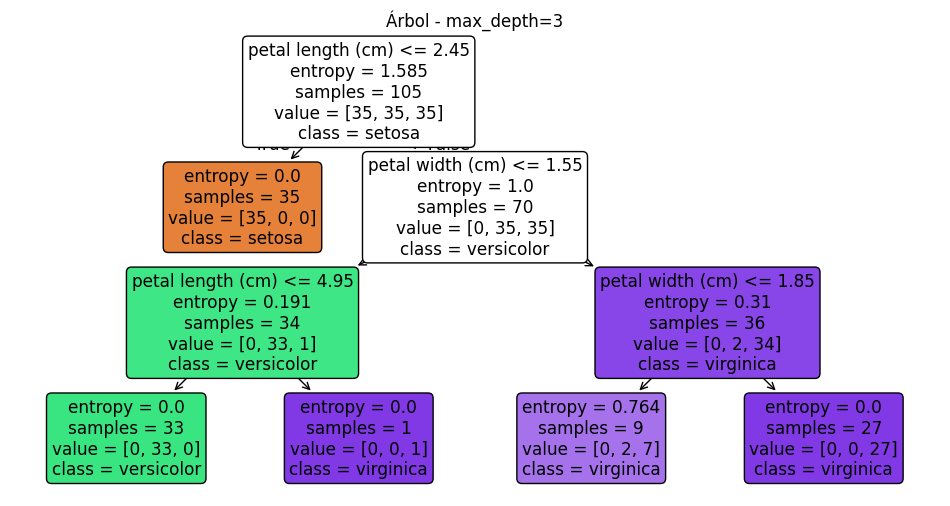

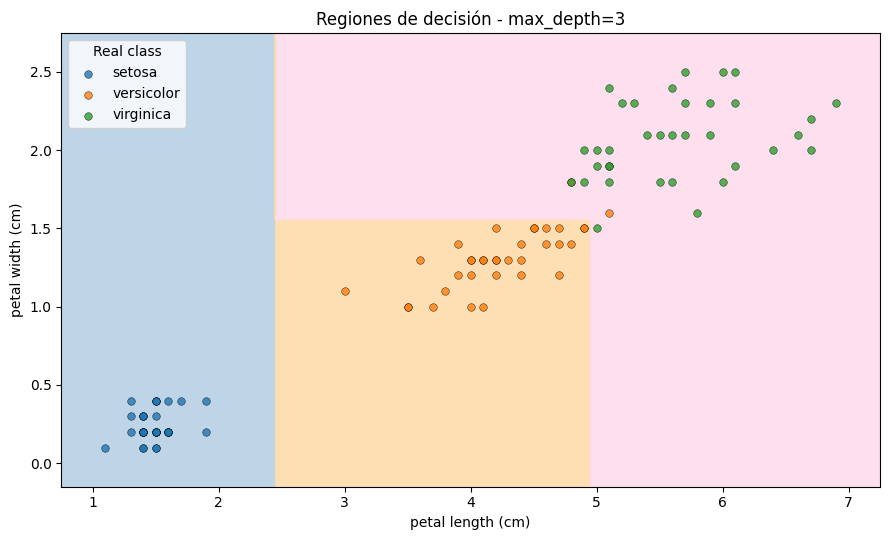

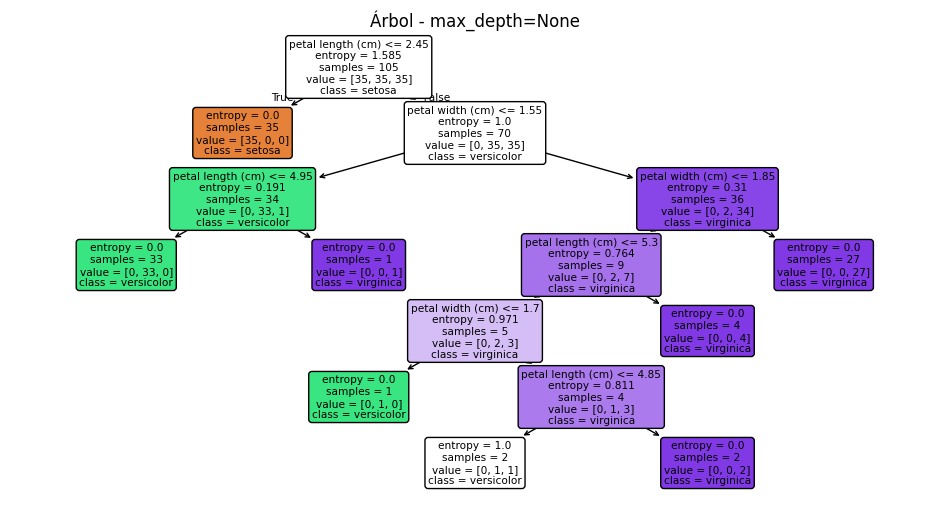

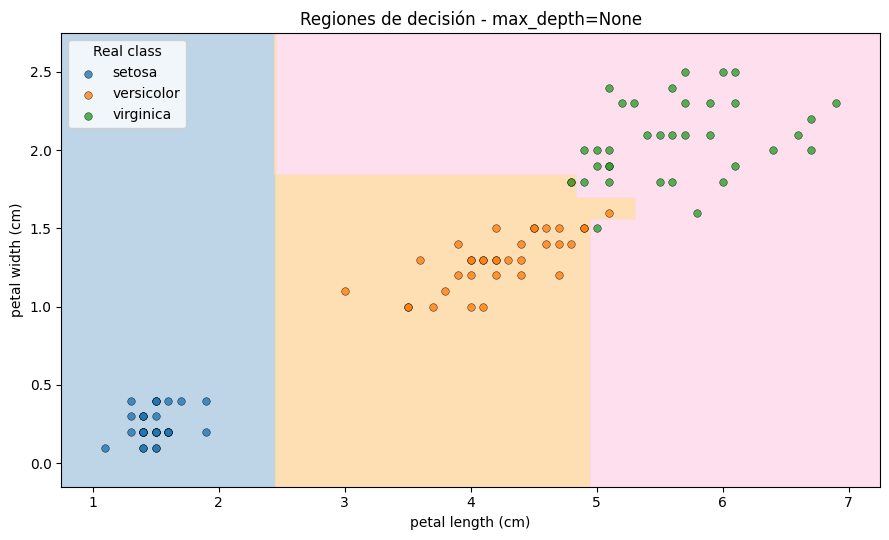

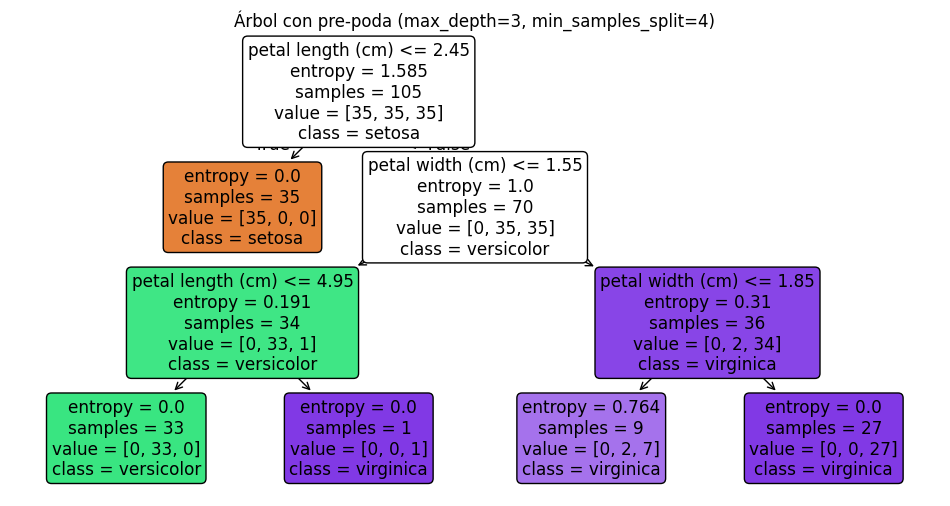

           modelo  profundidad  hojas  acc_train  acc_test
0     max_depth=2            2      3     0.9714    0.8889
1     max_depth=3            3      5     0.9810    0.9333
2  max_depth=None            6      8     0.9905    0.9333
3        pre-poda            3      5     0.9810    0.9333


In [12]:
#  1. Cargar Iris 
iris = load_iris()
X = iris.data[:, 2:4]   # columnas 2 y 3 = petal length y petal width
y = iris.target
feature_names = iris.feature_names[2:4]  
class_names = iris.target_names

# 70% entrenamiento y 30% prueba, estratificado para mantener la proporción de clases
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

# 2 y 3. Entrenar los tres modelos pedidos 
modelos = {
    "max_depth=2":    DecisionTreeClassifier(criterion="entropy", max_depth=2,    random_state=RANDOM_STATE),
    "max_depth=3":    DecisionTreeClassifier(criterion="entropy", max_depth=3,    random_state=RANDOM_STATE),
    "max_depth=None": DecisionTreeClassifier(criterion="entropy", max_depth=None, random_state=RANDOM_STATE),
}

filas = []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)

    # el arbol dibujado
    plt.figure(figsize=(12, 6))
    plot_tree(modelo, feature_names=feature_names, class_names=class_names,
              filled=True, rounded=True, impurity=True)
    plt.title(f"Árbol - {nombre}")
    plt.show()

    # Regiones de decisión (función de la profe), marcando los datos de entrenamiento
    plot_decision_regions(modelo, X_train, y_train, class_names, feature_names,
                          title=f"Regiones de decisión - {nombre}")

    # Métricas para la tabla comparativa
    filas.append({
        "modelo": nombre,
        "profundidad": modelo.get_depth(),
        "hojas": modelo.get_n_leaves(),
        "acc_train": accuracy_score(y_train, modelo.predict(X_train)),
        "acc_test":  accuracy_score(y_test,  modelo.predict(X_test)),
    })
resultados = pd.DataFrame(filas)

#4. Pre-poda
pre_poda = DecisionTreeClassifier(criterion="entropy", max_depth=3, min_samples_split=4, random_state=RANDOM_STATE)
pre_poda.fit(X_train, y_train)
plt.figure(figsize=(12, 6))
plot_tree(pre_poda, feature_names=feature_names, class_names=class_names,
          filled=True, rounded=True, impurity=True)
plt.title("Árbol con pre-poda (max_depth=3, min_samples_split=4)")
plt.show()

resultados_pre_poda = {
    "modelo": "pre-poda",
    "profundidad": pre_poda.get_depth(),
    "hojas": pre_poda.get_n_leaves(),
    "acc_train": accuracy_score(y_train, pre_poda.predict(X_train)),
    "acc_test":  accuracy_score(y_test,  pre_poda.predict(X_test)),
}
resultados = pd.concat([resultados, pd.DataFrame([resultados_pre_poda])], ignore_index=True)
print(resultados.round(4))

3) En este caso, se observa que sí aumentó el accuracy del modelo en cada paso, pero en general solo puede mantenerse o subir, y se satura en 1.
En cambio, en el accuracy del test se observa que subió de 2 a 3 y no cambió de 3 a None, lo que indica que la profundidad extra no aporto nada nuevo en los datos.

4) Al aplicar la pre-poda con `min_samples_leaf=4`, se obtiene un árbol de profundidad 3 y 5 hojas, en cambio el árbol sin límite alcanza una profundidad 6 y 8 hojas. Además, el árbol sin límite logra un accuracy de entrenamiento levemente mayor (0.9905 vs. 0.9810), pero el accuracy de prueba es idéntico en ambos (0.9333). Por lo tanto, la mayor complejidad no mejora la generalización y no podemos afirmar que el modelo sin límite generalice mejor que el de pre-poda. Dado que ambos rinden igual en datos nuevos, el árbol de pre-poda resulta preferible por ser más simple, ya que evita ajustar particularidades del conjunto de entrenamiento.

5) En `plot_tree`, **entropy** representa la inercia del nodo, donde esta es 0 cuando todas las muestras son de una misma clase y es 1 cuando las clases están mezcladas por igual, sino se calcula de la siguiente manera:

    $$I(s1) = − \frac{s_1}{S} \log_2(\frac{s_1}{S})$$
    Además, **samples** indica cuántas muestras de entrenamiento llegaron a ese nodo, **value** permite observar cuántas muestras de cada clase hay y **class** muestra la clase mayoritaria del nodo, que es la que predice el árbol si se queda ahí.

    En la raíz del árbol con `max_depth = 3` usa la condición petal length <= 2,45. En el gráfico de regiones esto corresponde a una línea vertical en x = 2,45, que separa la clase setosa de versicolor y virginica. Esto a su vez, coincide con el árbol, el nodo izquierdo tiene entropy = 0, con 35 muestra de setosa y el nodo derecho contiene 70 muestras mezcladas de las otras dos clases.